<a href="https://colab.research.google.com/github/harshaa24bms/BIS_Lab/blob/main/1BM24CS111_CS_DataCentreTemp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 1: Best Fitness = 5.5322
Iteration 2: Best Fitness = 5.5322
Iteration 3: Best Fitness = 5.5322
Iteration 4: Best Fitness = 5.3120
Iteration 5: Best Fitness = 5.0996
Iteration 6: Best Fitness = 5.0996
Iteration 7: Best Fitness = 4.9987
Iteration 8: Best Fitness = 4.9987
Iteration 9: Best Fitness = 4.9987
Iteration 10: Best Fitness = 4.9987
Iteration 11: Best Fitness = 4.9987
Iteration 12: Best Fitness = 4.9987
Iteration 13: Best Fitness = 4.9987
Iteration 14: Best Fitness = 4.9987
Iteration 15: Best Fitness = 4.8388
Iteration 16: Best Fitness = 4.8388
Iteration 17: Best Fitness = 4.8388
Iteration 18: Best Fitness = 4.8388
Iteration 19: Best Fitness = 4.8388
Iteration 20: Best Fitness = 4.8388
Iteration 21: Best Fitness = 4.8388
Iteration 22: Best Fitness = 4.8108
Iteration 23: Best Fitness = 4.8090
Iteration 24: Best Fitness = 4.8090
Iteration 25: Best Fitness = 4.8090
Iteration 26: Best Fitness = 4.8090
Iteration 27: Best Fitness = 4.8090
Iteration 28: Best Fitness = 4.8090
I

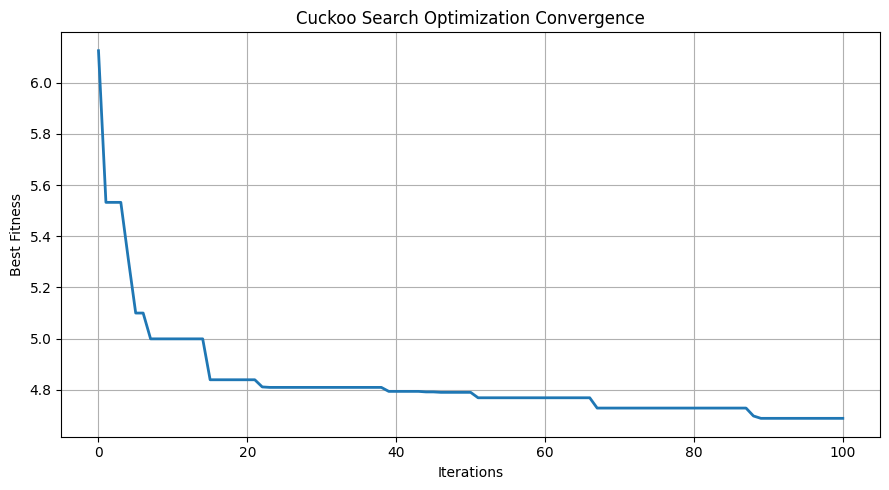

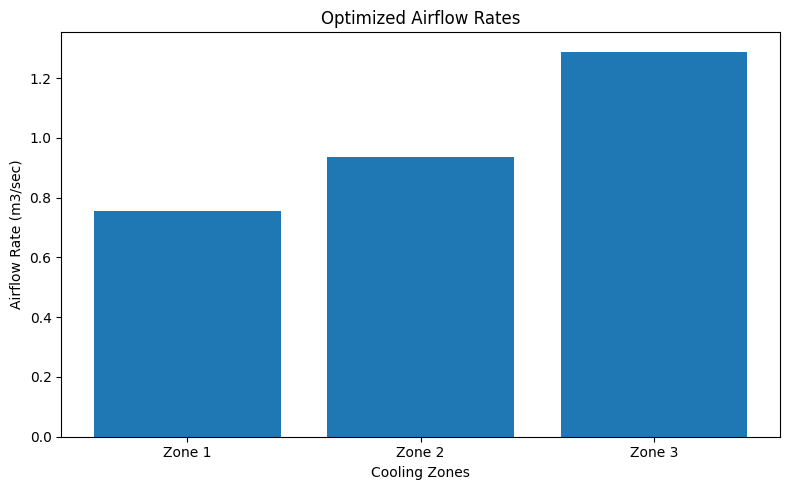

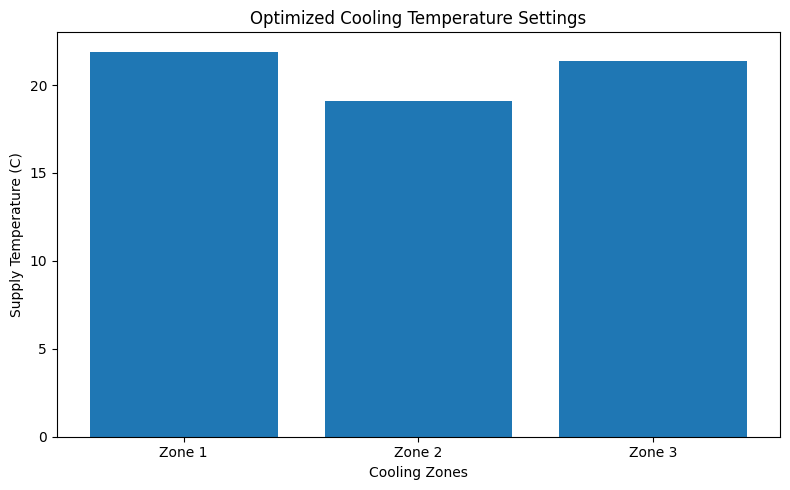

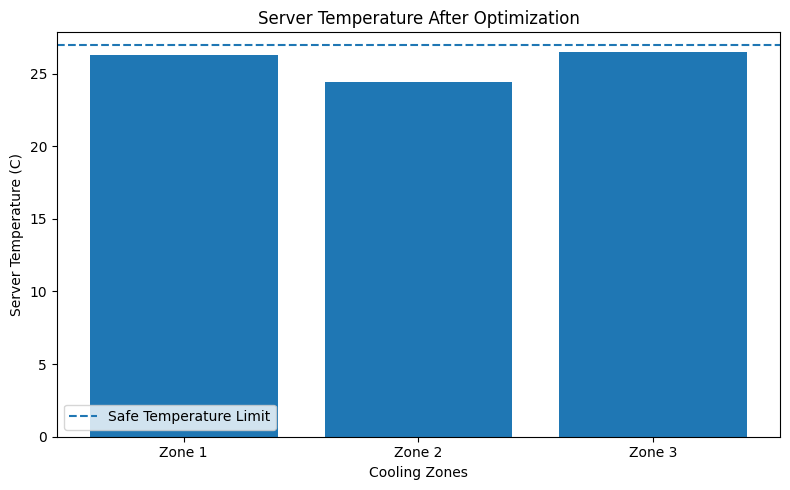

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import math

# ==========================================
# 1. DATA CENTER PARAMETERS
# ==========================================

N_ZONES = 3

# Heat load of each server zone (kW)
HEAT_LOAD = np.array([4.0, 6.0, 8.0])

# Maximum safe server temperature
SAFE_TEMP = 27.0

# Airflow limits (m3/sec)
MIN_AIRFLOW = 0.5
MAX_AIRFLOW = 4.0

# Cooling supply temperature limits (Celsius)
MIN_TEMP = 16.0
MAX_TEMP = 24.0

# Thermal constants
AIR_DENSITY = 1.2
SPECIFIC_HEAT = 1.005

# ==========================================
# 2. CUCKOO SEARCH PARAMETERS
# ==========================================

NESTS = 25
ITERATIONS = 100

PA = 0.25
ALPHA = 0.15
BETA = 1.5

rng = np.random.default_rng(42)

# Solution:
# [Airflow1, Airflow2, Airflow3,
#  SupplyTemp1, SupplyTemp2, SupplyTemp3]

LOWER = np.array(
    [MIN_AIRFLOW] * N_ZONES +
    [MIN_TEMP] * N_ZONES
)

UPPER = np.array(
    [MAX_AIRFLOW] * N_ZONES +
    [MAX_TEMP] * N_ZONES
)

DIMENSIONS = len(LOWER)


# ==========================================
# 3. PERFORMANCE CALCULATION
# ==========================================

def calculate_performance(solution):

    airflow = solution[:N_ZONES]
    supply_temp = solution[N_ZONES:]

    # Calculate server temperature
    server_temp = supply_temp + (
        HEAT_LOAD /
        (AIR_DENSITY * SPECIFIC_HEAT * airflow)
    )

    # Fan energy consumption
    fan_energy = 0.08 * np.sum(airflow ** 3)

    # Cooling coefficient of performance
    cop = 3.5 + 0.12 * (
        np.mean(supply_temp) - 16
    )

    # Cooling energy consumption
    cooling_energy = np.sum(HEAT_LOAD) / cop

    # Total energy
    total_energy = fan_energy + cooling_energy

    # Temperature violation penalty
    violation = np.maximum(
        0, server_temp - SAFE_TEMP
    )

    penalty = 1000 * np.sum(violation ** 2)

    # Minimize energy and temperature violations
    fitness = total_energy + penalty

    return (
        fitness,
        total_energy,
        server_temp,
        fan_energy,
        cooling_energy
    )


# ==========================================
# 4. LEVY FLIGHT FUNCTION
# ==========================================

def levy_flight():

    sigma = (
        math.gamma(1 + BETA)
        * math.sin(math.pi * BETA / 2)
        /
        (
            math.gamma((1 + BETA) / 2)
            * BETA
            * 2 ** ((BETA - 1) / 2)
        )
    ) ** (1 / BETA)

    u = rng.normal(0, sigma, DIMENSIONS)
    v = rng.normal(0, 1, DIMENSIONS)

    step = u / (
        np.abs(v) ** (1 / BETA) + 1e-10
    )

    return step


# ==========================================
# 5. INITIALIZE NESTS
# ==========================================

nests = rng.uniform(
    LOWER,
    UPPER,
    size=(NESTS, DIMENSIONS)
)

fitness_values = np.array([
    calculate_performance(nest)[0]
    for nest in nests
])

best_index = np.argmin(fitness_values)

best_nest = nests[best_index].copy()
best_fitness = fitness_values[best_index]

convergence = [best_fitness]


# ==========================================
# 6. CUCKOO SEARCH OPTIMIZATION
# ==========================================

for iteration in range(ITERATIONS):

    # Generate new solutions using Levy flight
    for i in range(NESTS):

        step = levy_flight()

        new_solution = (
            nests[i]
            + ALPHA * step * (UPPER - LOWER)
        )

        # Restrict values within allowed limits
        new_solution = np.clip(
            new_solution,
            LOWER,
            UPPER
        )

        new_fitness = calculate_performance(
            new_solution
        )[0]

        # Select a random nest
        j = rng.integers(0, NESTS)

        # Replace selected nest if new solution is better
        if new_fitness < fitness_values[j]:

            nests[j] = new_solution.copy()
            fitness_values[j] = new_fitness

    # Abandon a fraction of worst nests
    number_to_abandon = max(
        1, int(PA * NESTS)
    )

    worst_indices = np.argsort(
        fitness_values
    )[-number_to_abandon:]

    for j in worst_indices:

        nests[j] = rng.uniform(
            LOWER,
            UPPER
        )

        fitness_values[j] = calculate_performance(
            nests[j]
        )[0]

    # Update best solution
    best_index = np.argmin(fitness_values)

    if fitness_values[best_index] < best_fitness:

        best_nest = nests[best_index].copy()
        best_fitness = fitness_values[best_index]

    convergence.append(best_fitness)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Fitness = {best_fitness:.4f}"
    )


# ==========================================
# 7. FINAL RESULTS
# ==========================================

(
    final_fitness,
    total_energy,
    server_temp,
    fan_energy,
    cooling_energy
) = calculate_performance(best_nest)

airflow = best_nest[:N_ZONES]
supply_temp = best_nest[N_ZONES:]

print("\n========== OPTIMAL COOLING CONFIGURATION ==========")

for i in range(N_ZONES):

    print(f"\nCooling Zone {i + 1}")
    print(f"Heat Load: {HEAT_LOAD[i]:.2f} kW")
    print(f"Airflow Rate: {airflow[i]:.2f} m3/sec")
    print(f"Supply Temperature: {supply_temp[i]:.2f} C")
    print(f"Server Temperature: {server_temp[i]:.2f} C")

print("\n========== ENERGY CONSUMPTION ==========")

print(f"Fan Energy: {fan_energy:.2f} kW")
print(f"Cooling Energy: {cooling_energy:.2f} kW")
print(f"Total Energy: {total_energy:.2f} kW")
print(f"Fitness: {final_fitness:.4f}")

print("\nTemperature Safety Check:")

for i in range(N_ZONES):

    status = (
        "SAFE" if server_temp[i] <= SAFE_TEMP
        else "EXCEEDED"
    )

    print(f"Zone {i + 1}: {status}")


# ==========================================
# 8. GRAPH 1 - CONVERGENCE
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    convergence,
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Optimization Convergence")

plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# 9. GRAPH 2 - OPTIMAL AIRFLOW
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Zone 1", "Zone 2", "Zone 3"],
    airflow
)

plt.xlabel("Cooling Zones")
plt.ylabel("Airflow Rate (m3/sec)")
plt.title("Optimized Airflow Rates")

plt.tight_layout()
plt.show()


# ==========================================
# 10. GRAPH 3 - COOLING TEMPERATURE
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Zone 1", "Zone 2", "Zone 3"],
    supply_temp
)

plt.xlabel("Cooling Zones")
plt.ylabel("Supply Temperature (C)")
plt.title("Optimized Cooling Temperature Settings")

plt.tight_layout()
plt.show()


# ==========================================
# 11. GRAPH 4 - SERVER TEMPERATURE
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Zone 1", "Zone 2", "Zone 3"],
    server_temp
)

plt.axhline(
    y=SAFE_TEMP,
    linestyle="--",
    label="Safe Temperature Limit"
)

plt.xlabel("Cooling Zones")
plt.ylabel("Server Temperature (C)")
plt.title("Server Temperature After Optimization")

plt.legend()
plt.tight_layout()
plt.show()
